# 04 · GNN results on test (15 Nov, MIND dev)

The final, pre-registered test run (ADR 008, ADR 009). Configuration frozen on validation;
nothing below was used to make a decision.

| Model | What it is |
|---|---|
| **embedding** | frozen MiniLM article embeddings; user = mean of history embeddings; cosine score; **untrained** |
| **A0** | the GNN's architecture, loss and training, but **no edges**: each article vector comes only from its own text |
| **GNN** | the full model (ADR 007): article, subcategory, category, entity and entity-type nodes; pruned co-click edges |

Both trained models: refit on the test setup (training graph 9–12 Nov, examples 13–14 Nov, scoring graph
9–14 Nov), **fixed 9 epochs** (best validation epoch), **5 seeds (0–4)**.

**Win criterion (ADR 009):** every seed's paired-bootstrap 95% interval for the AUC difference on all test
impressions excludes zero, on the same side. **Primary comparison: GNN vs A0** ("does the graph help?").
Secondary: GNN vs embedding and A0 vs embedding.

Produced by `uv run python -m recsys.experiments.final_test train` then `... report`; this notebook only reads
`reports/gnn_test_*.csv`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from recsys.paths import FIGURES_DIR, REPORTS_DIR

INK, INK_SECONDARY, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COLORS = {"GNN vs A0 (primary)": "#2a78d6", "GNN vs embedding": "#eb6834", "A0 vs embedding": "#1baf7a"}
MODEL_COLORS = {"embedding": "#2a78d6", "a0": "#eb6834", "gnn": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK_SECONDARY, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})
SEGMENTS = ["all", "user=known", "user=new", "history=empty", "article=seen", "article=unseen"]

results = pd.read_csv(REPORTS_DIR / "gnn_test_results.csv")
boot = pd.read_csv(REPORTS_DIR / "gnn_test_bootstrap.csv")
verdicts = pd.read_csv(REPORTS_DIR / "gnn_test_verdicts.csv", index_col=0)
beyond = pd.read_csv(REPORTS_DIR / "gnn_test_beyond_accuracy.csv")

## 1. Verdicts (ADR 009 win criterion, AUC on all test impressions)

In [2]:
v = verdicts.copy()
v[["mean", "min", "max"]] = v[["mean", "min", "max"]].astype(float)
v.style.format({"mean": "{:+.4f}", "min": "{:+.4f}", "max": "{:+.4f}"})

,mean,min,max,seeds excluding 0,outcome
GNN vs A0 (primary),+0.0053,-0.0010,+0.0126,4,no win (not every seed's interval excludes zero on the same side)
GNN vs embedding,+0.0267,+0.0170,+0.0341,5,win for the first model
A0 vs embedding,+0.0214,+0.0180,+0.0260,5,win for the first model


In [3]:
per_seed = boot[(boot["metric"] == "auc") & (boot["segment"] == "all")]
per_seed.pivot(index="seed", columns="comparison", values="diff").round(4).assign(
    **{f"{c} 95% CI": per_seed[per_seed["comparison"] == c].set_index("seed")
       .apply(lambda r: f"[{r.ci_low:+.4f}, {r.ci_high:+.4f}]", axis=1) for c in COLORS})

comparison,A0 vs embedding,GNN vs A0 (primary),GNN vs embedding,GNN vs A0 (primary) 95% CI,GNN vs embedding 95% CI,A0 vs embedding 95% CI
seed,,,,,,
0,0.0199,0.0045,0.0244,"[+0.0029, +0.0062]","[+0.0223, +0.0264]","[+0.0179, +0.0220]"
1,0.0216,0.0126,0.0341,"[+0.0110, +0.0141]","[+0.0321, +0.0361]","[+0.0196, +0.0236]"
2,0.0218,0.0066,0.0284,"[+0.0051, +0.0083]","[+0.0264, +0.0304]","[+0.0199, +0.0237]"
3,0.0180,-0.0010,0.0170,"[-0.0024, +0.0005]","[+0.0150, +0.0191]","[+0.0160, +0.0200]"
4,0.0260,0.0036,0.0296,"[+0.0020, +0.0052]","[+0.0275, +0.0317]","[+0.0241, +0.0280]"


**Interpretation:** **The primary comparison does not meet the win criterion.** The GNN is ahead of A0 in 4 of 5
seeds (mean +0.0053 AUC, range −0.0010 to +0.0126), but seed 3's interval includes zero (−0.0010
[−0.0024, +0.0005]), so "the graph helps" is not established under the pre-registered rule. Both secondary
comparisons are clear wins: GNN over the embedding baseline in every seed (+0.027 mean) and A0 over the embedding
baseline in every seed (+0.021 mean). **Most of the gain over the untrained baseline comes from training on clicks**
(A0 alone gets about four fifths of it); the graph adds a smaller, seed-dependent amount on top.

## 2. Per-seed differences with 95% intervals

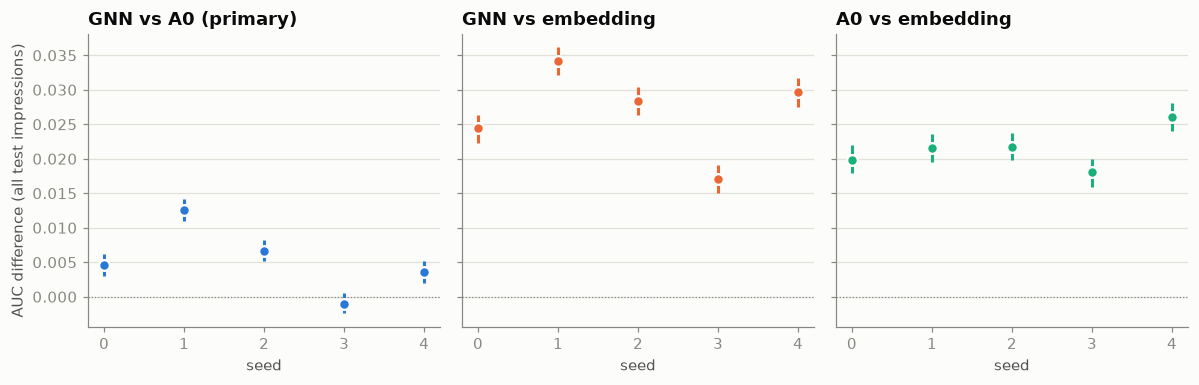

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, (comp, color) in zip(axes, COLORS.items()):
    r = per_seed[per_seed["comparison"] == comp].sort_values("seed")
    ax.axhline(0, color=MUTED, lw=0.8, ls=":")
    ax.errorbar(r["seed"], r["diff"], yerr=[r["diff"] - r["ci_low"], r["ci_high"] - r["diff"]],
                fmt="o", ms=7, color=color, mec="#fcfcfb", mew=1.5, elinewidth=2, capsize=0)
    ax.set_xticks(range(5))
    ax.set_xlabel("seed")
    ax.set_title(comp)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("AUC difference (all test impressions)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_test_seed_differences.png")
plt.show()

**Interpretation:** The secondary comparisons sit far from zero in every seed. GNN vs A0 is small and positive for four
seeds, and seed 3 straddles zero. The intervals are narrow (±0.0015), so the spread *between* seeds, not the data
noise within a seed, is what decides the primary comparison, exactly the situation the 5-seed rule was written for.

## 3. Accuracy by model and segment (mean over seeds, with range)

In [5]:
def summary(metric):
    g = results.groupby(["segment", "model"])[metric]
    t = g.mean().unstack()[["embedding", "a0", "gnn"]].loc[SEGMENTS]
    rng = (g.max() - g.min()).unstack()[["a0", "gnn"]].loc[SEGMENTS]
    out = t.copy()
    for m in ("a0", "gnn"):
        out[m] = [f"{t.loc[s, m]:.4f} (±{rng.loc[s, m] / 2:.4f})" for s in SEGMENTS]
    out["embedding"] = t["embedding"].map("{:.4f}".format)
    return out

n = results[results["model"] == "embedding"].set_index("segment")["n_impressions"].loc[SEGMENTS]
print("AUC (trained models: mean over 5 seeds, ± half the range)")
display(summary("auc").assign(impressions=n.map("{:,}".format)))
print("nDCG@10")
display(summary("ndcg@10"))

AUC (trained models: mean over 5 seeds, ± half the range)


model,embedding,a0,gnn,impressions
segment,,,,
all,0.6369,0.6583 (±0.0040),0.6636 (±0.0086),"73,152"
user=known,0.6475,0.6637 (±0.0067),0.6687 (±0.0079),"8,959"
user=new,0.6354,0.6576 (±0.0036),0.6629 (±0.0086),"64,193"
history=empty,0.5000,0.5679 (±0.0041),0.5709 (±0.0160),"1,955"
article=seen,0.6361,0.6621 (±0.0039),0.6680 (±0.0102),"59,233"
article=unseen,0.6346,0.6520 (±0.0095),0.6672 (±0.0062),"21,676"


nDCG@10


model,embedding,a0,gnn
segment,,,
all,0.3936,0.4048 (±0.0029),0.4140 (±0.0054)
user=known,0.4002,0.4091 (±0.0055),0.4185 (±0.0055)
user=new,0.3927,0.4042 (±0.0026),0.4133 (±0.0054)
history=empty,0.2987,0.3390 (±0.0043),0.3426 (±0.0088)
article=seen,0.4210,0.4358 (±0.0033),0.4448 (±0.0066)
article=unseen,0.5923,0.6015 (±0.0060),0.6108 (±0.0044)


**Interpretation:** The GNN has the highest mean AUC in every segment. Against A0 the margin is largest on **unseen
articles** (0.667 vs 0.652), and that segment's per-seed differences are positive in all five seeds (see section 4).
**This is the opposite of validation**, where the GNN and A0 trailed the embedding baseline on unseen articles
(`reports/gnn_ablations.md`, round 3). The test day differs from the validation day (a later graph with 9–14 Nov
co-clicks and more articles around each new one), so this is reported as a finding; it changes no decision. Empty-history
users (1,955 impressions) are where training helps most relative to the untrained baseline, which can only produce ties for them.

## 4. Paired differences by segment (mean over seeds, min to max)

In [6]:
b = boot[boot["metric"] == "auc"]
agg = b.groupby(["comparison", "segment"])["diff"].agg(["mean", "min", "max"])
excl = b.assign(x=(b["ci_low"] > 0) | (b["ci_high"] < 0)).groupby(["comparison", "segment"])["x"].sum()
table = agg.assign(**{"seeds excluding 0": excl}).reset_index()
table = table[table["segment"].isin(SEGMENTS)]
table["segment"] = pd.Categorical(table["segment"], SEGMENTS)
(table.sort_values(["comparison", "segment"]).set_index(["comparison", "segment"])
 .style.format({"mean": "{:+.4f}", "min": "{:+.4f}", "max": "{:+.4f}"}))

**Interpretation:** For GNN vs A0, unseen articles are the only segment where **all five seeds** favour the graph and
exclude zero (+0.012 to +0.019). On seen articles the graph's contribution changes sign across seeds (−0.005 to +0.014); on known
users it is positive in every seed but small (+0.001 to +0.012), with only 2 of 5 intervals excluding zero. Per ADR 009 these segment results are reported, not decided on; the primary verdict is the "all" row.

## 5. Beyond accuracy (top 5 per impression)

- **Freshness exposure:** share of top-5 slots given to articles unseen in 9–14 Nov, against their share of clicks (23.2%).
- **Coverage:** share of distinct candidate articles that appear in at least one impression's top 5.
- **Diversity:** mean number of distinct subcategories among an impression's top 5.

Ties (the embedding baseline scores every candidate equally for empty-history users) are broken at random, with a fixed seed.

In [7]:
cols = ["unseen share of top-5 slots", "coverage (candidates in any top 5)", "diversity (distinct subcategories in top 5)"]
g = beyond.groupby("model")[cols]
ba = g.mean().loc[["embedding", "a0", "gnn"]]
ba_rng = (g.max() - g.min()).loc[["embedding", "a0", "gnn"]]
display(pd.DataFrame({c: [f"{ba.loc[m, c]:.3f}" + ("" if m == "embedding" else f" (±{ba_rng.loc[m, c] / 2:.3f})")
                          for m in ba.index] for c in cols}, index=ba.index))
print(f"Unseen share of clicks: {beyond['unseen share of clicks'].iloc[0]:.3f}; "
      f"of candidate rows: {beyond['unseen share of candidate rows'].iloc[0]:.3f}")

,unseen share of top-5 slots,coverage (candidates in any top 5),diversity (distinct subcategories in top 5)
model,,,
embedding,0.222,0.522,4.084
a0,0.247 (±0.011),0.470 (±0.009),4.183 (±0.008)
gnn,0.285 (±0.010),0.488 (±0.009),3.905 (±0.041)


Unseen share of clicks: 0.232; of candidate rows: 0.200


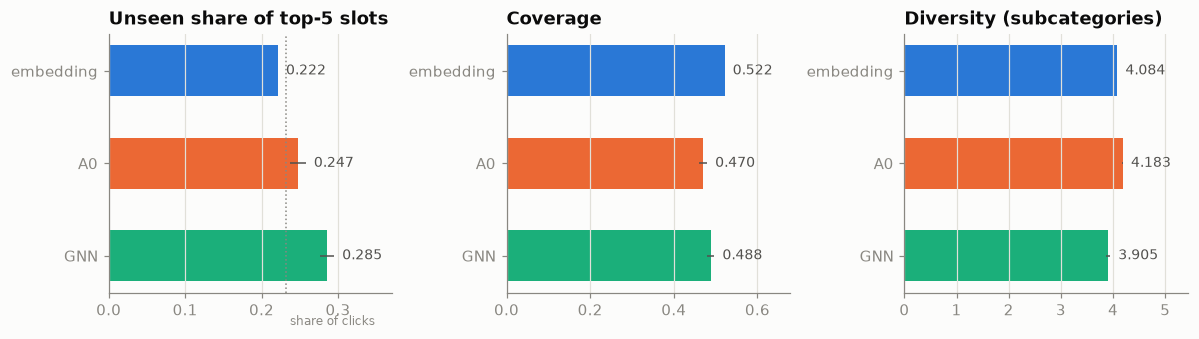

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
labels = {"embedding": "embedding", "a0": "A0", "gnn": "GNN"}
for ax, col, title in zip(axes, cols, ["Unseen share of top-5 slots", "Coverage", "Diversity (subcategories)"]):
    y = range(3)[::-1]
    ax.barh(list(y), ba[col], color=[MODEL_COLORS[m] for m in ba.index], height=0.55,
            xerr=[ba_rng[col] / 2], error_kw={"ecolor": INK_SECONDARY, "elinewidth": 1})
    ax.set_yticks(list(y), [labels[m] for m in ba.index])
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    for yi, m in zip(y, ba.index):
        ax.text(ba.loc[m, col] + ba_rng.loc[m, col] / 2, yi, f"  {ba.loc[m, col]:.3f}", va="center", fontsize=9,
                color=INK_SECONDARY)
    ax.set_xlim(0, ba[col].max() * 1.3)  # bars start at zero
axes[0].axvline(beyond["unseen share of clicks"].iloc[0], color=MUTED, ls=":", lw=1)
axes[0].text(beyond["unseen share of clicks"].iloc[0], -0.75, " share of clicks", fontsize=8, color=MUTED)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_test_beyond_accuracy.png")
plt.show()

**Interpretation:**

- **Freshness:** the GNN gives unseen articles **28–30%** of top-5 slots, more than their 23.2% share of clicks. A0 gives them 25% and the
  embedding baseline 22%. The GNN surfaces new articles slightly *beyond* what users clicked, consistent with its unseen-article
  AUC gain.
- **Coverage:** the embedding baseline spreads its top 5 over the most distinct articles (52%); the trained models concentrate more
  (GNN 48–50%, A0 46–48%), as expected from learning what users click.
- **Diversity:** the GNN's top 5 spans the fewest subcategories (3.9 vs 4.1–4.2). Its neighbourhoods pull same-topic articles together,
  which is the flip side of the near-duplicate issue noted for Milestone 4 (`reports/milestone3_gaps.md`).

## Conclusions

1. **Pre-registered primary result: no win for the graph.** GNN vs A0 is positive in 4 of 5 seeds (mean +0.005 AUC), but seed 3's
   interval includes zero, so under ADR 009 the graph's contribution is not established.
2. **Training on clicks is the main source of gain.** Both trained models clearly beat the untrained embedding baseline in every
   seed (+0.021 for A0, +0.027 for the GNN), so about four fifths of the GNN's gain needs no graph.
3. **Where the graph may matter: unseen articles.** On test the GNN beats A0 on unseen articles in all five seeds (+0.012 to +0.019)
   and puts more new articles in the top 5. This contradicts validation, where the trained models trailed on unseen articles. It is
   the most promising direction, and the first thing to explain before building on it.
4. **Beyond accuracy, the trade-off is fewer subcategories per list** (3.9 vs 4.1) for more freshness; diversity-aware re-ranking
   and near-duplicate removal belong in Milestone 4.